# First Data exploration

In [3]:
#import packages
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

### 1. Load electricity data

In [4]:

ROOT = Path.cwd()

if ROOT.name == "code":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed"
FIGURES = ROOT / "output" / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    DATA / "electricity_daily.csv",
    parse_dates=["date"]
)

df = df.sort_values("date").reset_index(drop=True)

print("First date:", df["date"].min())
print("Last date:", df["date"].max())
print("Total observations:", len(df))

display(df.head())

First date: 2017-01-01 00:00:00
Last date: 2026-11-08 00:00:00
Total observations: 3599


,date,consumption_mwh,intervals
0,2017-01-01,2995.518444,96
1,2017-01-02,3772.522678,96
2,2017-01-03,3959.535000,96
3,2017-01-04,4011.139465,96
4,2017-01-05,4028.828359,96


### 2. Plot the complete electricity consumption time series

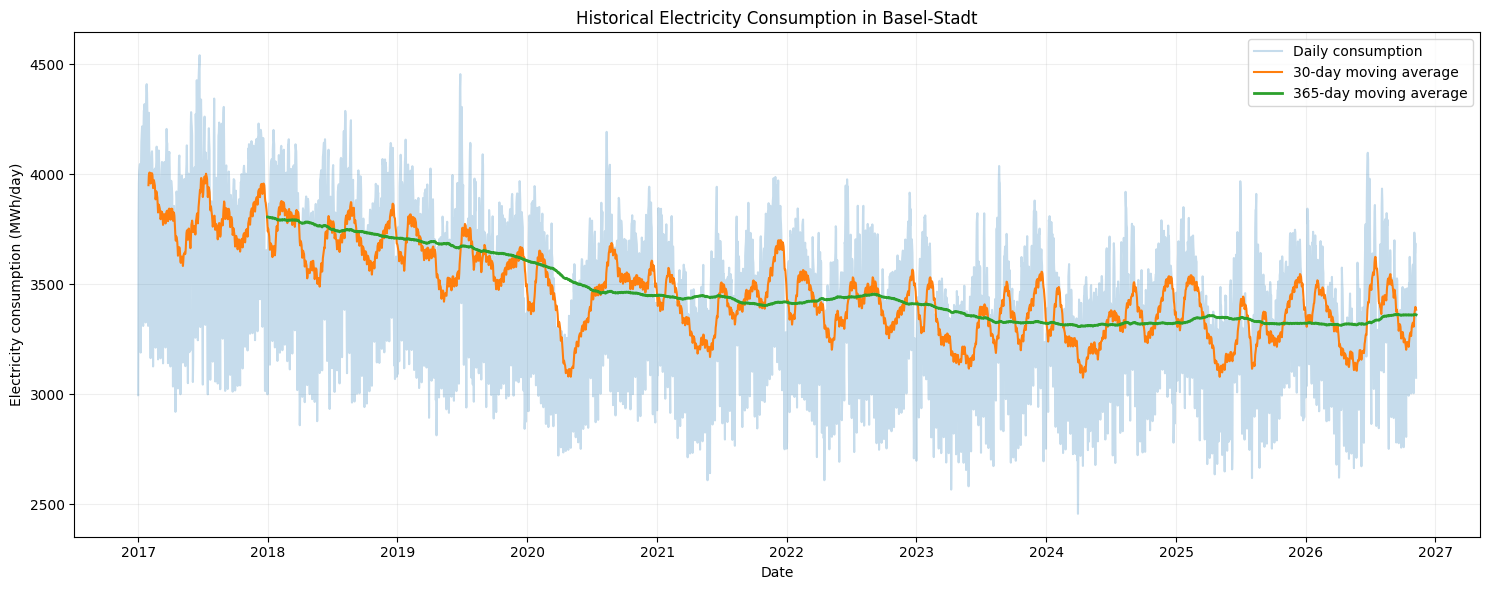

In [5]:
df["rolling_30d"] = (
    df["consumption_mwh"]
    .rolling(window=30)
    .mean()
)

df["rolling_365d"] = (
    df["consumption_mwh"]
    .rolling(window=365)
    .mean()
)

plt.figure(figsize=(15, 6))

plt.plot(
    df["date"],
    df["consumption_mwh"],
    label="Daily consumption",
    alpha=0.25
)

plt.plot(
    df["date"],
    df["rolling_30d"],
    label="30-day moving average",
    linewidth=1.5
)

plt.plot(
    df["date"],
    df["rolling_365d"],
    label="365-day moving average",
    linewidth=2
)

plt.title(
    "Historical Electricity Consumption in Basel-Stadt"
)
plt.xlabel("Date")
plt.ylabel("Electricity consumption (MWh/day)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES / "01_electricity_full_series.png",
    dpi=300
)

plt.show()

### 3. Compare annual electricity consumption

#### 3.1 annual consumption

In [6]:
df["year"] = df["date"].dt.year

annual = (
    df.groupby("year")
    .agg(
        average_consumption=("consumption_mwh", "mean"),
        total_consumption=("consumption_mwh", "sum"),
        days=("consumption_mwh", "count")
    )
)

annual["change_pct"] = (
    annual["average_consumption"].pct_change() * 100
)

display(annual.round(2))

,average_consumption,total_consumption,days,change_pct
year,,,,
2017,3805.33,1388947.00,365,NaN
2018,3709.27,1353884.73,365,-2.52
2019,3607.74,1316826.54,365,-2.74
2020,3448.63,1262200.34,366,-4.41
2021,3418.52,1247758.39,365,-0.87
2022,3410.00,1244650.69,365,-0.25
2023,3321.42,1212319.44,365,-2.60
2024,3323.59,1216434.02,366,0.07
2025,3322.70,1212784.81,365,-0.03


#### 3.2 Annual average consumption chart

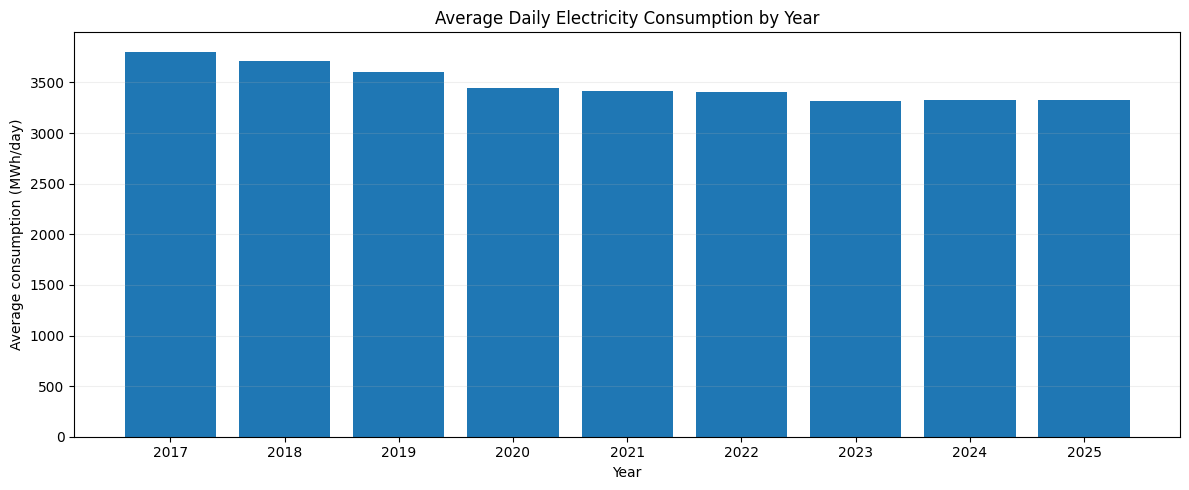

In [7]:
# Only compare complete calendar years
complete_years = annual[
    annual.index.map(
        lambda year: (
            pd.Timestamp(year + 1, 1, 1)
            - pd.Timestamp(year, 1, 1)
        ).days
    ) == annual["days"]
]

plt.figure(figsize=(12, 5))

plt.bar(
    complete_years.index.astype(str),
    complete_years["average_consumption"]
)

plt.title(
    "Average Daily Electricity Consumption by Year"
)
plt.xlabel("Year")
plt.ylabel("Average consumption (MWh/day)")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES / "02_annual_average_consumption.png",
    dpi=300
)

plt.show()

## 4. Examine monthly seasonality

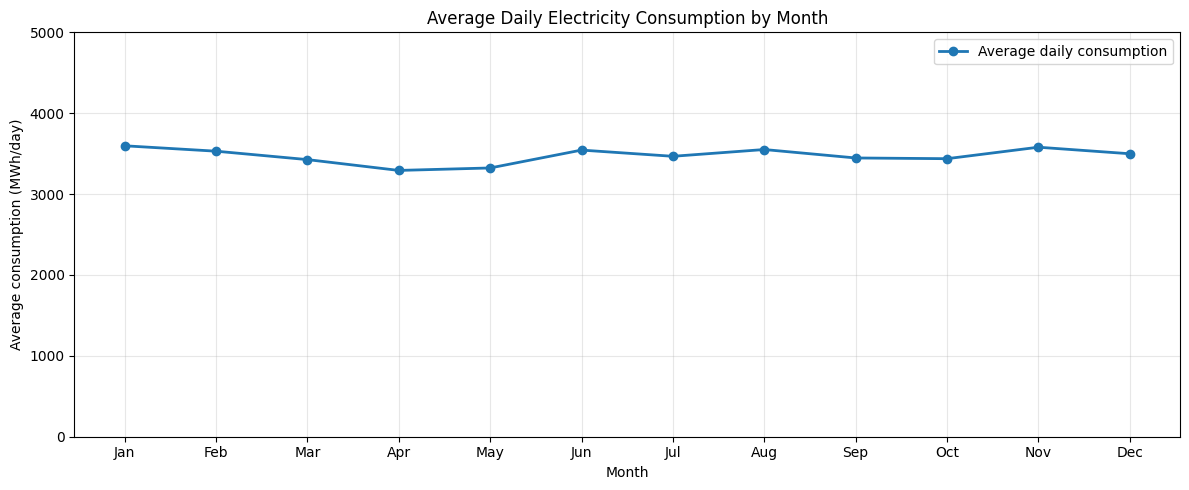

In [20]:
# Extract month from the date
df["month"] = df["date"].dt.month

# Calculate average daily electricity consumption for each month
monthly = (
    df.groupby("month")["consumption_mwh"]
    .mean()
)

# Create line plot
plt.figure(figsize=(12, 5))

plt.plot(
    monthly.index,
    monthly.values,
    marker="o",
    linewidth=2,
    markersize=6,
    label="Average daily consumption"
)

plt.title("Average Daily Electricity Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average consumption (MWh/day)")

# Display month names
plt.xticks(
    range(1, 13),
    [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

# Start Y-axis at zero
plt.ylim(bottom=0, top= 5000)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# Save figure
plt.savefig(
    FIGURES / "03_monthly_seasonality.png",
    dpi=300
)

plt.show()